In [ ]:
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python
!pip install "opencv-python-headless<5"

Found existing installation: opencv-python-headless 4.14.0.94
Uninstalling opencv-python-headless-4.14.0.94:
  Successfully uninstalled opencv-python-headless-4.14.0.94
  Using cached opencv_python_headless-4.14.0.94-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
Using cached opencv_python_headless-4.14.0.94-cp37-abi3-manylinux_2_28_x86_64.whl (62.0 MB)


In [ ]:
import cv2, time, joblib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

IMG_SIZE      = 32
MAX_PER_CLASS = 200
AUG_COPIES    = 1
N_BACKGROUND  = 1500
CONF_THRESH   = 0.60
RANDOM_STATE  = 42
rng = np.random.RandomState(RANDOM_STATE)

CLASS_NAMES = [
 'Speed limit 20','Speed limit 30','Speed limit 50','Speed limit 60','Speed limit 70','Speed limit 80',
 'End of speed limit 80','Speed limit 100','Speed limit 120','No passing','No passing (>3.5t)',
 'Right-of-way at intersection','Priority road','Yield','Stop','No vehicles','Vehicles >3.5t prohibited',
 'No entry','General caution','Dangerous curve left','Dangerous curve right','Double curve','Bumpy road',
 'Slippery road','Road narrows right','Road work','Traffic signals','Pedestrians','Children crossing',
 'Bicycles crossing','Beware ice/snow','Wild animals crossing','End of all limits','Turn right ahead',
 'Turn left ahead','Ahead only','Go straight or right','Go straight or left','Keep right','Keep left',
 'Roundabout mandatory','End of no passing','End of no passing (>3.5t)','BACKGROUND']
BG = 43

In [ ]:
from datasets import load_dataset

class DS:
    """Makes a Hugging Face dataset behave like the torchvision one: ds[i] -> (PIL image, label)"""
    def __init__(self, hf, img_col, lbl_col='label'):
        self.hf, self.img_col = hf, img_col
        self.labels = np.array(hf[lbl_col])
    def __len__(self):
        return len(self.hf)
    def __getitem__(self, i):
        i = int(i)
        return self.hf[i][self.img_col], int(self.labels[i])

train_ds = DS(load_dataset('tanganke/gtsrb', split='train'), 'image')
test_ds  = DS(load_dataset('tanganke/gtsrb', split='test'),  'image')
cifar    = DS(load_dataset('uoft-cs/cifar10', split='train'), 'img')
print(len(train_ds), len(test_ds), len(cifar))

26640 12630 50000


In [ ]:
def pil_to_bgr(p):
    return cv2.cvtColor(np.array(p.convert('RGB')), cv2.COLOR_RGB2BGR)

labels_all = train_ds.labels
idx = []
for c in range(43):
    c_idx = np.where(labels_all == c)[0]
    if MAX_PER_CLASS and len(c_idx) > MAX_PER_CLASS:
        c_idx = rng.choice(c_idx, MAX_PER_CLASS, replace=False)
    idx.extend(c_idx)
sign_imgs   = [pil_to_bgr(train_ds[i][0]) for i in idx]
sign_labels = list(labels_all[idx])

X_test_raw = [pil_to_bgr(test_ds[i][0]) for i in range(len(test_ds))]
y_test     = test_ds.labels
print(len(sign_imgs), 'train |', len(X_test_raw), 'test')

8330 train | 12630 test


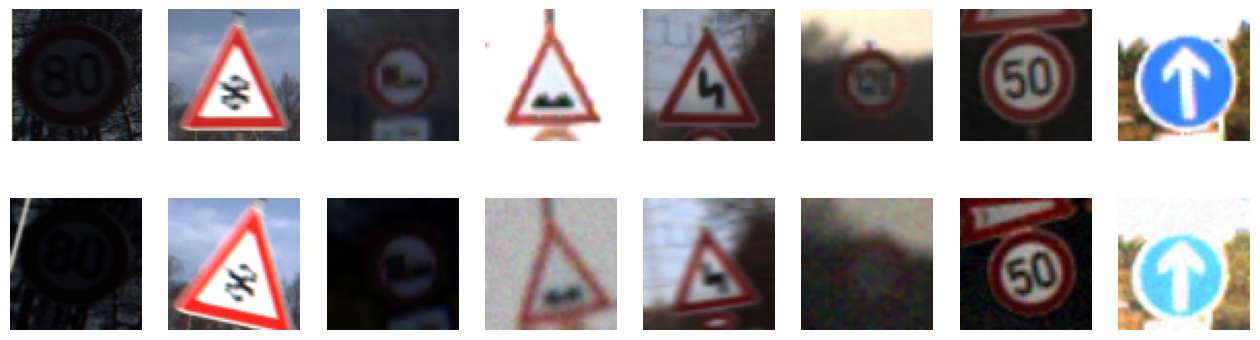

In [ ]:
def augment(img):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-15, 15), rng.uniform(0.85, 1.15))
    M[:, 2] += rng.uniform(-0.08, 0.08, 2) * [w, h]
    out = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)
    out = cv2.convertScaleAbs(out, alpha=rng.uniform(0.5, 1.5), beta=rng.uniform(-50, 50))
    r = rng.rand()
    if r < 0.25:
        out = cv2.GaussianBlur(out, (5, 5), 0)
    elif r < 0.45:
        k = np.zeros((5, 5), np.float32); k[2, :] = 1 / 5
        out = cv2.filter2D(out, -1, k)
    if rng.rand() < 0.4:
        out = np.clip(out + rng.normal(0, 8, out.shape), 0, 255).astype(np.uint8)
    return out

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for k in range(8):
    i = rng.randint(len(sign_imgs))
    axes[0, k].imshow(cv2.cvtColor(cv2.resize(sign_imgs[i], (64, 64)), cv2.COLOR_BGR2RGB))
    axes[1, k].imshow(cv2.cvtColor(cv2.resize(augment(sign_imgs[i]), (64, 64)), cv2.COLOR_BGR2RGB))
    axes[0, k].axis('off'); axes[1, k].axis('off')
plt.show()

In [ ]:
bg_imgs = []
for i in rng.choice(len(cifar), N_BACKGROUND, replace=False):
    im = pil_to_bgr(cifar[int(i)][0])
    if rng.rand() < 0.5:
        s = rng.randint(12, 28); x, y = rng.randint(0, 32 - s, 2)
        im = im[y:y + s, x:x + s]
    bg_imgs.append(cv2.resize(im, (48, 48)))
for _ in range(300):
    base = rng.randint(0, 255, 3).astype(np.uint8)
    patch = np.tile(base, (48, 48, 1)) + rng.normal(0, 6, (48, 48, 3))
    bg_imgs.append(np.clip(patch, 0, 255).astype(np.uint8))

train_imgs, train_labels = list(sign_imgs), list(sign_labels)
for im, lb in zip(sign_imgs, sign_labels):
    for _ in range(AUG_COPIES):
        train_imgs.append(augment(im)); train_labels.append(lb)
train_imgs += bg_imgs; train_labels += [BG] * len(bg_imgs)
y_train = np.array(train_labels)
print('Total training samples:', len(train_imgs))

Total training samples: 18460


In [ ]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))

def preprocess(img_bgr):
    img = cv2.resize(img_bgr, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    img = cv2.GaussianBlur(img, (3, 3), 0)
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    lab[:, :, 0] = clahe.apply(lab[:, :, 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

hog = cv2.HOGDescriptor(_winSize=(IMG_SIZE, IMG_SIZE), _blockSize=(16, 16),
                        _blockStride=(8, 8), _cellSize=(8, 8), _nbins=9)

def extract_features(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    hog_feat = hog.compute(gray).ravel()
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    h = cv2.calcHist([hsv], [0], None, [16], [0, 180])
    s = cv2.calcHist([hsv], [1], None, [8], [0, 256])
    v = cv2.calcHist([hsv], [2], None, [8], [0, 256])
    col = np.concatenate([h, s, v]).ravel()
    col /= (col.sum() + 1e-7)
    return np.concatenate([hog_feat, col]).astype(np.float32)

feat = lambda im: extract_features(preprocess(im))

t0 = time.time()
X_train = np.array([feat(im) for im in train_imgs])
X_test  = np.array([feat(im) for im in X_test_raw])
print(X_train.shape, X_test.shape, '%.1fs' % (time.time() - t0))

(18460, 356) (12630, 356) 9.6s


In [ ]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2,
                                            stratify=y_train, random_state=RANDOM_STATE)

def make_pipe(clf):
    return Pipeline([('scaler', StandardScaler()),
                     ('pca', PCA(n_components=0.95, random_state=RANDOM_STATE)),
                     ('clf', clf)])

knn = GridSearchCV(make_pipe(KNeighborsClassifier()),
                   {'clf__n_neighbors': [1, 3, 5], 'clf__weights': ['uniform', 'distance']},
                   cv=3, n_jobs=-1).fit(X_tr, y_tr)
print('k-NN best:', knn.best_params_, '| val acc %.4f' % knn.score(X_val, y_val))

t0 = time.time()
svm = GridSearchCV(make_pipe(SVC(kernel='rbf', gamma='scale')),
                   {'clf__C': [5, 20]}, cv=3, n_jobs=-1).fit(X_tr, y_tr)
print('SVM best:', svm.best_params_, '| val acc %.4f' % svm.score(X_val, y_val), '| %.0fs' % (time.time() - t0))

k-NN best: {'clf__n_neighbors': 5, 'clf__weights': 'distance'} | val acc 0.8567
SVM best: {'clf__C': 5} | val acc 0.9228 | 141s


In [ ]:
t0 = time.time()
best_C = svm.best_params_['clf__C']
model = make_pipe(SVC(kernel='rbf', C=best_C, gamma='scale', probability=True,
                      random_state=RANDOM_STATE)).fit(X_train, y_train)
print('Trained in %.0fs' % (time.time() - t0))
joblib.dump(model, 'traffic_sign_svm.pkl')

Trained in 112s


['traffic_sign_svm.pkl']

k-NN test accuracy: 0.6867
SVM  test accuracy: 0.8722


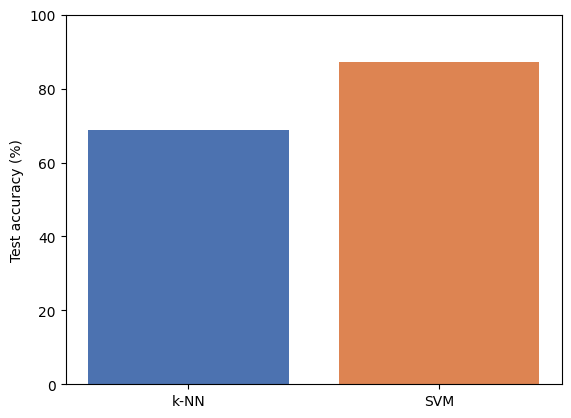

                              precision    recall  f1-score   support

              Speed limit 20      0.552     0.617     0.583        60
              Speed limit 30      0.803     0.867     0.834       720
              Speed limit 50      0.851     0.776     0.812       750
              Speed limit 60      0.839     0.798     0.818       450
              Speed limit 70      0.925     0.902     0.913       660
              Speed limit 80      0.668     0.773     0.717       630
       End of speed limit 80      0.956     0.867     0.909       150
             Speed limit 100      0.929     0.811     0.866       450
             Speed limit 120      0.794     0.796     0.795       450
                  No passing      0.938     0.973     0.955       480
          No passing (>3.5t)      0.967     0.971     0.969       660
Right-of-way at intersection      0.870     0.862     0.866       420
               Priority road      0.973     0.984     0.978       690
                   

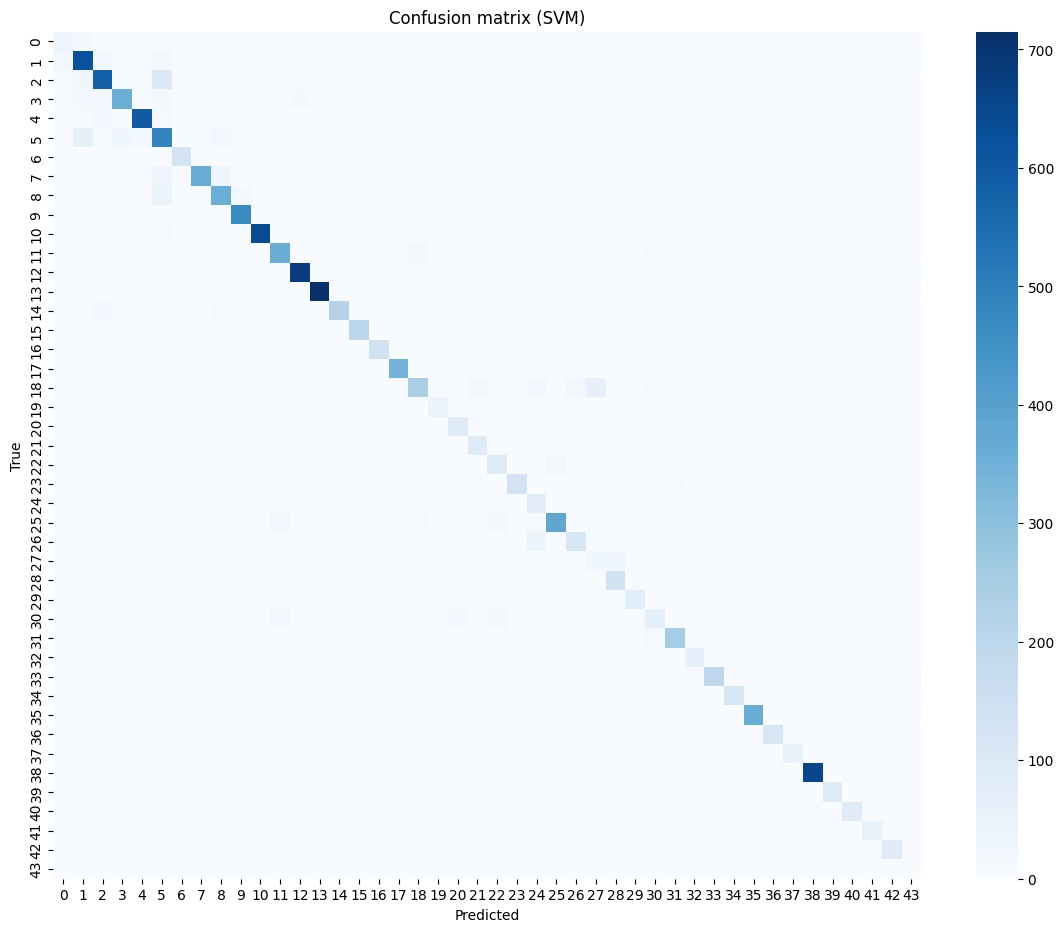

In [ ]:
pred_knn = knn.best_estimator_.predict(X_test)
pred_svm = model.predict(X_test)
print('k-NN test accuracy: %.4f' % accuracy_score(y_test, pred_knn))
print('SVM  test accuracy: %.4f' % accuracy_score(y_test, pred_svm))

plt.bar(['k-NN', 'SVM'], [accuracy_score(y_test, pred_knn) * 100, accuracy_score(y_test, pred_svm) * 100],
        color=['#4C72B0', '#DD8452']); plt.ylim(0, 100); plt.ylabel('Test accuracy (%)'); plt.show()

print(classification_report(y_test, pred_svm, labels=list(range(43)),
                            target_names=CLASS_NAMES[:43], digits=3, zero_division=0))

cm = confusion_matrix(y_test, pred_svm, labels=list(range(44)))
plt.figure(figsize=(14, 11)); sns.heatmap(cm, cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix (SVM)'); plt.show()

In [ ]:
def colour_mask(bgr):
    hsv = cv2.cvtColor(cv2.GaussianBlur(bgr, (5, 5), 0), cv2.COLOR_BGR2HSV)
    red1 = cv2.inRange(hsv, (0, 90, 60),   (10, 255, 255))
    red2 = cv2.inRange(hsv, (165, 90, 60), (180, 255, 255))
    blue = cv2.inRange(hsv, (100, 120, 50), (130, 255, 255))
    yell = cv2.inRange(hsv, (15, 110, 120), (35, 255, 255))
    mask = red1 | red2 | blue | yell
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k, iterations=2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k, iterations=1)
    return mask

def find_candidates(bgr, min_frac=0.0004, max_frac=0.25):
    H, W = bgr.shape[:2]
    mask = colour_mask(bgr)
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for c in cnts:
        x, y, w, h = cv2.boundingRect(c)
        area_frac = (w * h) / float(W * H)
        aspect = w / float(h)
        fill = cv2.contourArea(c) / float(w * h)
        if min_frac < area_frac < max_frac and 0.6 < aspect < 1.5 and fill > 0.30 and min(w, h) >= 16:
            pad = int(0.12 * max(w, h))
            x0, y0 = max(0, x - pad), max(0, y - pad)
            x1, y1 = min(W, x + w + pad), min(H, y + h + pad)
            boxes.append((x0, y0, x1 - x0, y1 - y0))
    return boxes, mask

def nms(dets, iou_thr=0.3):
    if not dets: return []
    b = [list(map(int, d[:4])) for d in dets]; s = [float(d[4]) for d in dets]
    keep = cv2.dnn.NMSBoxes(b, s, 0.0, iou_thr)
    return [dets[int(i)] for i in np.array(keep).flatten()]

In [ ]:
def detect_and_classify(bgr, conf_thresh=CONF_THRESH, max_side=1000):
    h, w = bgr.shape[:2]
    if max(h, w) > max_side:
        f = max_side / float(max(h, w))
        bgr = cv2.resize(bgr, None, fx=f, fy=f, interpolation=cv2.INTER_AREA)
    boxes, mask = find_candidates(bgr)
    dets = []
    if boxes:
        feats = np.array([feat(bgr[y:y + h_, x:x + w_]) for x, y, w_, h_ in boxes])
        probs = model.predict_proba(feats)
        classes = model.classes_
        for (x, y, w_, h_), p in zip(boxes, probs):
            j = int(np.argmax(p)); label, score = int(classes[j]), float(p[j])
            if label != BG and score >= conf_thresh:
                dets.append((x, y, w_, h_, score, label))
    return nms(dets), bgr, mask, boxes

def draw(bgr, dets):
    out = bgr.copy()
    for x, y, w, h, s, lb in dets:
        cv2.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), 2)
        txt = '%s %.0f%%' % (CLASS_NAMES[lb], s * 100)
        (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
        cv2.rectangle(out, (x, max(0, y - th - 6)), (x + tw + 4, y), (0, 255, 0), -1)
        cv2.putText(out, txt, (x + 2, max(th, y - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1, cv2.LINE_AA)
    return out

def show_result(bgr, title=''):
    dets, img, mask, boxes = detect_and_classify(bgr)
    fig, ax = plt.subplots(1, 3, figsize=(20, 6))
    ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title('Input ' + title)
    ax[1].imshow(mask, cmap='gray'); ax[1].set_title('Colour mask (%d candidates)' % len(boxes))
    ax[2].imshow(cv2.cvtColor(draw(img, dets), cv2.COLOR_BGR2RGB)); ax[2].set_title('Detected: %d sign(s)' % len(dets))
    for a in ax: a.axis('off')
    plt.show()
    for d in dets: print('  ->', CLASS_NAMES[d[5]], '(%.0f%%)' % (d[4] * 100))
    return dets

Ground truth: ['Speed limit 100', 'Speed limit 30', 'General caution', 'Keep right']


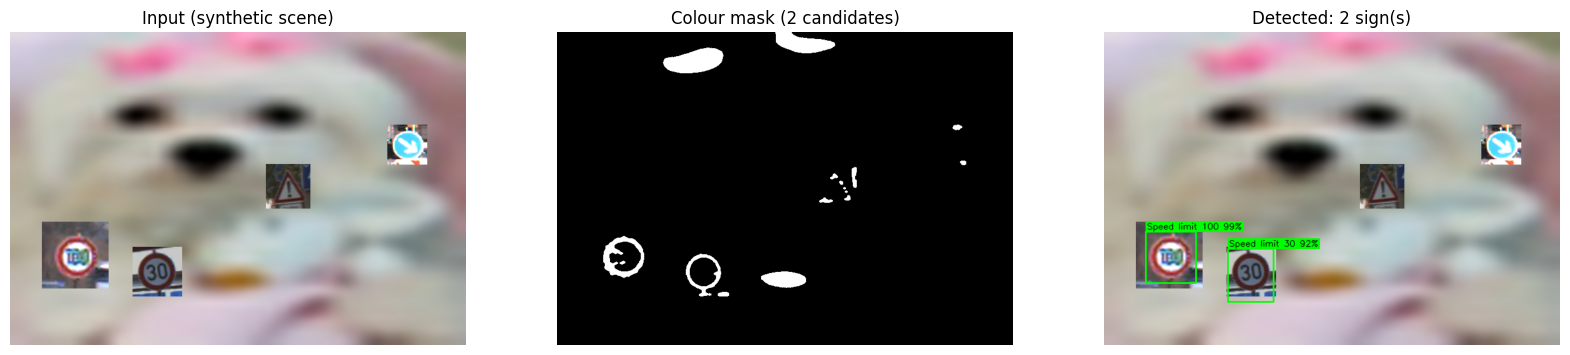

  -> Speed limit 100 (99%)
  -> Speed limit 30 (92%)


In [ ]:
def make_demo_scene(n_signs=4, W=800, H=550):
    bg = pil_to_bgr(cifar[int(rng.randint(len(cifar)))][0])
    scene = cv2.GaussianBlur(cv2.resize(bg, (W, H), interpolation=cv2.INTER_CUBIC), (15, 15), 0)
    truth, slot = [], W // n_signs
    for k in range(n_signs):
        i = int(rng.randint(len(test_ds)))
        size = int(rng.randint(70, 120))
        sign = cv2.resize(X_test_raw[i], (size, size), interpolation=cv2.INTER_CUBIC)
        sign = cv2.convertScaleAbs(sign, alpha=rng.uniform(0.7, 1.3), beta=rng.uniform(-25, 25))
        x = k * slot + int(rng.randint(10, max(11, slot - size - 10)))
        y = int(rng.randint(40, H - size - 40))
        scene[y:y + size, x:x + size] = sign
        truth.append(CLASS_NAMES[y_test[i]])
    return scene, truth

scene, truth = make_demo_scene()
print('Ground truth:', truth)
_ = show_result(scene, '(synthetic scene)')

Saving pedestrian-0.3.jpg to pedestrian-0.3 (2).jpg

== pedestrian-0.3 (2).jpg (600, 600, 3)


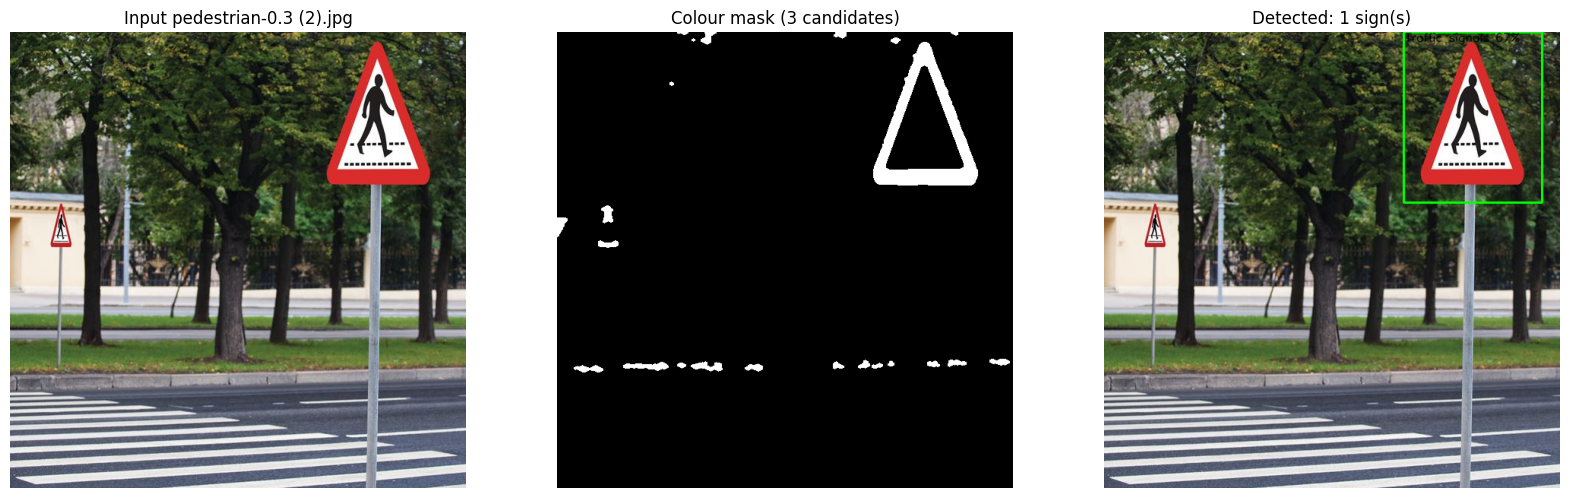

  -> Traffic signals (67%)


In [ ]:
from google.colab import files
uploaded = files.upload()
for name in uploaded:
    im = cv2.imread(name)
    print('\n==', name, im.shape)
    show_result(im, name)

In [ ]:
def process_video(src, dst='annotated.mp4', max_frames=600, skip=2):
    cap = cv2.VideoCapture(src)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    f = 960 / max(W, H) if max(W, H) > 960 else 1.0
    out = cv2.VideoWriter(dst, cv2.VideoWriter_fourcc(*'mp4v'), fps / skip, (int(W * f), int(H * f)))
    n = 0
    while n < max_frames:
        ok, frame = cap.read()
        if not ok: break
        if n % skip == 0:
            if f != 1.0: frame = cv2.resize(frame, (int(W * f), int(H * f)))
            dets, img, _, _ = detect_and_classify(frame)
            out.write(draw(img, dets))
        n += 1
    cap.release(); out.release()
    print('Processed', n, 'frames ->', dst)

vid = files.upload()
process_video(list(vid)[0])
files.download('annotated.mp4')

Saving sample_speed_limit_drive.mp4 to sample_speed_limit_drive.mp4
Processed 300 frames -> annotated.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>